In [2]:
# pandas/numpy for data handling, scikit-learn for splitting, tuning and metrics,
# XGBoost/LightGBM for gradient-boosted tree models, pickle for saving objects
import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split , RandomizedSearchCV
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import mean_absolute_error , mean_squared_error , r2_score

from xgboost import XGBRegressor
from lightgbm import LGBMRegressor

import pickle

In [6]:
# Load the raw dataset
df = pd.read_csv("demand_forecasting.csv")

In [7]:
# List all available columns before choosing features
df.columns

Index(['Date', 'Store ID', 'Product ID', 'Category', 'Region',
       'Inventory Level', 'Units Sold', 'Units Ordered', 'Price', 'Discount',
       'Weather Condition', 'Promotion', 'Competitor Pricing', 'Seasonality',
       'Epidemic', 'Demand'],
      dtype='object')

In [12]:
# Inputs a planner knows BEFORE the selling period.
# Units Sold is deliberately excluded: it is only known after the fact and would leak the answer
features = [
    "Price" ,
    "Discount" ,
    "Inventory Level" ,
    "Promotion" ,
    "Competitor Pricing" ,
    "Category"
]

In [9]:
# Confirm the selected features
features

['Price',
 'Discount',
 'Inventory Level',
 'Promotion',
 'Competitor Pricing ',
 'Category']

In [10]:
# The value we want to predict
target = "Demand"

In [13]:
# Feature matrix (a copy, so encoding below doesn't change the original df)
X = df[features].copy()

In [14]:
# Preview the feature matrix
X

,Price,Discount,Inventory Level,Promotion,Competitor Pricing,Category
0,72.72,5,195,0,85.73,Electronics
1,80.16,15,117,1,92.02,Clothing
2,62.94,10,247,1,60.08,Clothing
3,87.63,10,139,0,85.19,Electronics
4,54.41,0,152,0,51.63,Groceries
...,...,...,...,...,...,...
75995,29.80,5,233,0,32.23,Toys
75996,42.92,5,137,0,40.73,Toys
75997,17.81,10,197,0,19.41,Clothing
75998,151.72,0,125,0,143.71,Furniture


In [15]:
# Target vector
Y = df[target]

In [16]:
# Preview the target
Y

,Demand
0,115
1,229
2,157
3,52
4,59
...,...
75995,64
75996,137
75997,68
75998,84


Converting strings to Categorical model

In [17]:
# Find the text (object) columns that need to be converted to numbers
label_encoders = {}
# We define label_encoders = {} at the start to store a separate, trained LabelEncoder instance for each of our categorical columns.

categorical_cols = X.select_dtypes(include ="object").columns

In [18]:
# Only Category needs encoding
categorical_cols

Index(['Category'], dtype='object')

In [19]:
# Replace each category name with an integer code and keep the fitted encoder,
# so the app can apply exactly the same mapping to user input later
for col in categorical_cols:
  le = LabelEncoder()
  X[col] = le.fit_transform(X[col])
  label_encoders[col] = le

In [20]:
# Check the stored encoders
label_encoders

{'Category': LabelEncoder()}

Spliting into the training and Test set

In [21]:
# Hold out 20% of the rows to measure performance on data the model has never seen
X_train , X_test , Y_train , Y_test = train_test_split(X, Y, test_size = 0.2)

In [ ]:
# Linear model training involve scaling
# XgBoost follows Tree Based Algo, no need of scaling ( like decision tree or random forest )

XgBoost Base Model

In [22]:
# Base XGBoost regressor; squared-error loss, using all CPU cores
xbg =  XGBRegressor(objective ="reg:squarederror" ,n_jobs = -1)

Hyper-parameter tuning for getting best preformance , as base model do not offer that

In [23]:
# Search space for tuning:
# n_estimators = number of trees, max_depth = tree depth, learning_rate = step size,
# subsample / colsample_bytree = share of rows / columns used per tree (reduces overfitting),
# min_child_weight = minimum data needed to make a split
param_dict = {
    "n_estimators" : [200 , 300 , 500],
    "max_depth" : [3,4,6,8],
    "learning_rate" : [0.01,0.05 , 0.1],
    "subsample" : [0.8,0.9,1],
    "colsample_bytree" : [0.7,0.8,1],
    "min_child_weight" : [1,3,5 ]

}

In [ ]:
# initialising Randomised Search

In [25]:
# Try 25 random combinations from the grid, scoring each with 3-fold cross-validation
# and keeping the one with the lowest mean absolute error
random_search  = RandomizedSearchCV(
    estimator = xbg,
    param_distributions = param_dict,
    n_iter = 25,
    scoring = "neg_mean_absolute_error",
    cv = 3,
    verbose = 1,
    n_jobs = -1
)

In [26]:
# Run the search on the training set (25 combinations x 3 folds = 75 fits)
random_search.fit(X_train, Y_train)

Fitting 3 folds for each of 25 candidates, totalling 75 fits


RandomizedSearchCV(cv=3,
                   estimator=XGBRegressor(base_score=None, booster=None,
                                          callbacks=None,
                                          colsample_bylevel=None,
                                          colsample_bynode=None,
                                          colsample_bytree=None, device=None,
                                          early_stopping_rounds=None,
                                          enable_categorical=True,
                                          eval_metric=None, feature_types=None,
                                          feature_weights=None, gamma=None,
                                          grow_policy=None,
                                          importance_type=None,
                                          interaction_constraints...
                                          monotone_constraints=None,
                                          multi_strategy=None,
                                          n_estimators=None, n_jobs=-1,
                                          num_parallel_tree=None, ...),
                   n_iter=25, n_jobs=-1,
                   param_distributions={'colsample_bytree': [0.7, 0.8, 1],
                                        'learning_rate': [0.01, 0.05, 0.1],
                                        'max_depth': [3, 4, 6, 8],
                                        'min_child_weight': [1, 3, 5],
                                        'n_estimators': [200, 300, 500],
                                        'subsample': [0.8, 0.9, 1]},
                   scoring='neg_mean_absolute_error', verbose=1)

In [27]:
# Best hyperparameters found
random_search.best_params_

{'subsample': 0.8,
 'n_estimators': 500,
 'min_child_weight': 3,
 'max_depth': 8,
 'learning_rate': 0.01,
 'colsample_bytree': 1}

In [28]:
# Model refitted on the full training set with the best hyperparameters
best_model = random_search.best_estimator_

In [29]:
# Predict demand for the held-out test rows
y_pred  =  best_model.predict(X_test)

In [31]:
# RMSE: typical prediction error in units of demand (lower is better)
np.sqrt(mean_squared_error(Y_test, y_pred))

np.float64(35.818016386332204)

In [32]:
# How much each feature contributes to the model's predictions
#Feature modeling

best_model.feature_importances_

array([0.05038083, 0.01212557, 0.01141658, 0.71053123, 0.014059  ,
       0.20148675], dtype=float32)

In [33]:
# Label the importances with feature names and sort, most important first
feature_importance = pd.Series(
    best_model.feature_importances_,
    index = X.columns
).sort_values(ascending = False)

In [34]:
# Show the ranked importances
feature_importance

,0
Promotion,0.710531
Category,0.201487
Price,0.050381
Competitor Pricing,0.014059
Discount,0.012126
Inventory Level,0.011417


<Axes: title={'center': 'Feature_importance'}>

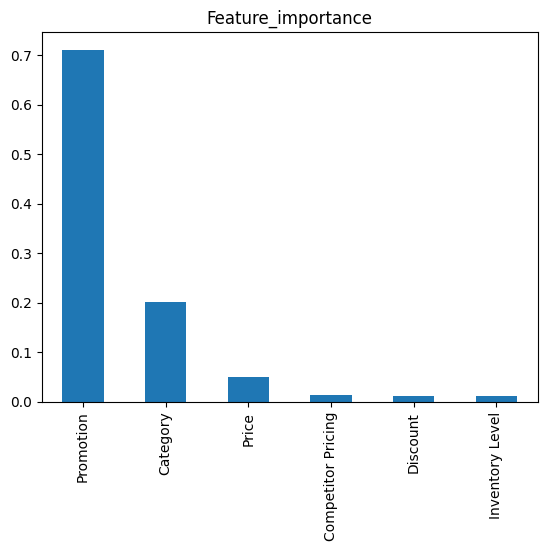

In [36]:
# Bar chart of feature importance
feature_importance.plot(kind = "bar" ,title = "Feature_importance")

In [37]:
# Save the fitted encoders so the Streamlit app can encode Category the same way
with open("lable_encoders.pkl" , "wb") as f:
  pickle.dump(label_encoders , f)

In [38]:
# Save the trained model in XGBoost's native JSON format (the file app.py loads);
# unlike pickle, it stays loadable across XGBoost library versions
best_model.save_model("xgboost_demand_model.json")